# 05 – Final evaluation on the test set

The final models were trained with three seeds (42, 123, 2026) by `src/run_final.py`, using only the training and validation splits. This notebook evaluates them **once** on the official MIT-BIH test set (21,892 beats). Nothing below is used to change a model or a setting.

Results are reported as mean ± standard deviation over the three seeds. For the residual CNN, two configurations are included: without imbalance handling (A) and the configuration selected in notebook 04 (D: oversampling + augmentation).

In [1]:
import os
import sys
import json
sys.path.append("..")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras

from src.data import load_mitbih, CLASS_NAMES
from src.evaluate import compute_metrics, summary_row, plot_confusion_matrix, FIG_DIR, METRICS_DIR, RESULTS_DIR
from src.run_final import SEEDS, RUN_ORDER, KERAS_MODELS, FINAL_METRICS_DIR, FINAL_MODEL_DIR

plt.rcParams.update({"font.size": 11, "axes.titlesize": 13, "axes.labelsize": 12})

LABELS = {
    "logreg": "Logistic Regression",
    "rf_balanced": "Random Forest (balanced)",
    "mlp": "MLP",
    "simple_cnn": "Simple 1D CNN",
    "resnet_cnn": "Residual CNN (A)",
    "resnet_cnn_D": "Residual CNN (D, final)",
    "lstm": "LSTM",
}

In [2]:
X_test, y_test = load_mitbih("test")
print("Test:", X_test.shape)
pd.Series(np.bincount(y_test), index=CLASS_NAMES, name="test beats")

Test: (21892, 187)


N    18118
S      556
V     1448
F      162
Q     1608
Name: test beats, dtype: int64

## 1. Predictions on the test set

In [3]:
def load_model(name, seed):
    if name in KERAS_MODELS:
        return keras.models.load_model(FINAL_MODEL_DIR / f"{name}_seed{seed}.keras")
    return joblib.load(FINAL_MODEL_DIR / f"{name}_seed{seed}.joblib")


def predict(model, name, X):
    if name in KERAS_MODELS:
        return model.predict(X, batch_size=1024, verbose=0).argmax(axis=1)
    return model.predict(X)


test_preds, test_metrics, val_metrics = {}, {}, {}
for name in RUN_ORDER:
    for seed in SEEDS:
        y_pred = predict(load_model(name, seed), name, X_test)
        test_preds[name, seed] = y_pred
        test_metrics[name, seed] = compute_metrics(y_test, y_pred)
        with open(FINAL_METRICS_DIR / f"{name}_seed{seed}.json") as f:
            val_metrics[name, seed] = json.load(f)["metrics"]
    print(f"{LABELS[name]:<26} test macro F1: "
          + ", ".join(f"{test_metrics[name, s]['macro_f1']:.4f}" for s in SEEDS))

with open(FINAL_METRICS_DIR / "test_metrics.json", "w") as f:
    json.dump({f"{name}_seed{seed}": m for (name, seed), m in test_metrics.items()}, f, indent=2, default=float)

Logistic Regression        test macro F1: 0.6641, 0.6641, 0.6641


Random Forest (balanced)   test macro F1: 0.8894, 0.8884, 0.8913


MLP                        test macro F1: 0.8903, 0.8909, 0.8969


Simple 1D CNN              test macro F1: 0.9137, 0.9112, 0.9189


Residual CNN (A)           test macro F1: 0.9221, 0.9016, 0.9317


Residual CNN (D, final)    test macro F1: 0.9300, 0.9223, 0.9232


LSTM                       test macro F1: 0.8798, 0.1846, 0.8696


## 2. Failed training runs

A run is counted as failed if it never left the trivial solution of predicting N for every beat. This is decided on the **validation set** before looking at the test results: predicting N for every validation beat gives a macro F1 of 0.18, so a run with validation macro F1 below 0.3 is marked as failed. Failed runs are left out of the mean ± std but are reported here.

In [4]:
failed = [(n, s) for n in RUN_ORDER for s in SEEDS if val_metrics[n, s]["macro_f1"] < 0.3]

pd.DataFrame([{"model": LABELS[n], "seed": s,
               "val macro F1": round(val_metrics[n, s]["macro_f1"], 3),
               "test macro F1": round(test_metrics[n, s]["macro_f1"], 3),
               "test recall N": round(test_metrics[n, s]["per_class"]["N"]["recall"], 3)}
              for n, s in failed])

,model,seed,val macro F1,test macro F1,test recall N
0,LSTM,123,0.184,0.185,1.0


## 3. Final comparison table (test set, mean ± std over seeds)

In [5]:
rows = pd.DataFrame([{**summary_row(name, test_metrics[name, seed]), "seed": seed,
                      "converged": (name, seed) not in failed}
                     for name in RUN_ORDER for seed in SEEDS])
rows.to_csv(METRICS_DIR / "final_test_per_seed.csv", index=False)

metric_cols = ["accuracy", "balanced_accuracy", "macro_f1", "recall_S", "recall_V", "recall_F"]
ok = rows[rows["converged"]]
agg = ok.groupby("model", sort=False)[metric_cols].agg(["mean", "std"])
agg[("runs", "n")] = ok.groupby("model", sort=False).size()
agg.to_csv(METRICS_DIR / "final_test_summary.csv")
n_runs = agg[("runs", "n")]

table = pd.DataFrame({col: [f"{agg.loc[n, (col, 'mean')]:.3f} ± {agg.loc[n, (col, 'std')]:.3f}" for n in agg.index]
                      for col in metric_cols}, index=[LABELS[n] for n in agg.index])
table["converged runs"] = [f"{k}/{len(SEEDS)}" for k in n_runs]
table

,accuracy,balanced_accuracy,macro_f1,recall_S,recall_V,recall_F,converged runs
Logistic Regression,0.915 ± 0.000,0.597 ± 0.000,0.664 ± 0.000,0.421 ± 0.000,0.334 ± 0.000,0.364 ± 0.000,3/3
Random Forest (balanced),0.977 ± 0.000,0.865 ± 0.002,0.890 ± 0.001,0.714 ± 0.002,0.926 ± 0.002,0.730 ± 0.016,3/3
MLP,0.980 ± 0.000,0.857 ± 0.006,0.893 ± 0.004,0.671 ± 0.003,0.935 ± 0.006,0.708 ± 0.025,3/3
Simple 1D CNN,0.985 ± 0.000,0.889 ± 0.001,0.915 ± 0.004,0.779 ± 0.005,0.956 ± 0.004,0.730 ± 0.013,3/3
Residual CNN (A),0.985 ± 0.004,0.904 ± 0.016,0.918 ± 0.015,0.800 ± 0.048,0.964 ± 0.002,0.772 ± 0.038,3/3
"Residual CNN (D, final)",0.986 ± 0.001,0.935 ± 0.001,0.925 ± 0.004,0.864 ± 0.002,0.959 ± 0.005,0.868 ± 0.007,3/3
LSTM,0.976 ± 0.002,0.836 ± 0.016,0.875 ± 0.007,0.648 ± 0.017,0.912 ± 0.022,0.660 ± 0.026,2/3


Validation vs test macro F1 (mean over converged runs). A large drop from validation to test would mean that the model choices were overfitted to the validation set.

In [6]:
pd.DataFrame({
    "validation": [np.mean([val_metrics[n, s]["macro_f1"] for s in SEEDS if (n, s) not in failed]) for n in RUN_ORDER],
    "test": [np.mean([test_metrics[n, s]["macro_f1"] for s in SEEDS if (n, s) not in failed]) for n in RUN_ORDER],
}, index=[LABELS[n] for n in RUN_ORDER]).round(3)

,validation,test
Logistic Regression,0.657,0.664
Random Forest (balanced),0.901,0.890
MLP,0.907,0.893
Simple 1D CNN,0.926,0.915
Residual CNN (A),0.925,0.918
"Residual CNN (D, final)",0.935,0.925
LSTM,0.891,0.875


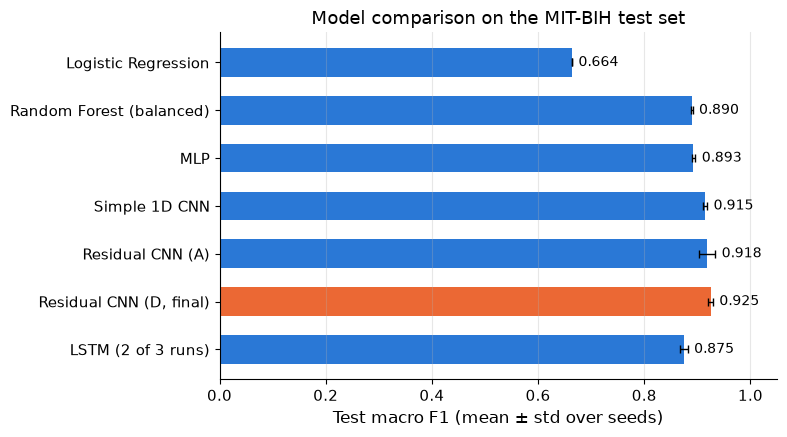

In [7]:
means = agg[("macro_f1", "mean")].reindex(RUN_ORDER)
stds = agg[("macro_f1", "std")].reindex(RUN_ORDER)

fig, ax = plt.subplots(figsize=(8, 4.5))
y = np.arange(len(RUN_ORDER))[::-1]
colors = ["#eb6834" if n == "resnet_cnn_D" else "#2a78d6" for n in RUN_ORDER]
ax.barh(y, means, xerr=stds, color=colors, height=0.6, capsize=3, error_kw={"elinewidth": 1})
for yi, m, s in zip(y, means, stds):
    ax.text(m + s + 0.012, yi, f"{m:.3f}", va="center", fontsize=10)
labels = [LABELS[n] if n_runs[n] == len(SEEDS) else f"{LABELS[n]} ({n_runs[n]} of {len(SEEDS)} runs)"
          for n in RUN_ORDER]
ax.set_yticks(y, labels)
ax.set_xlim(0, 1.05)
ax.set_xlabel("Test macro F1 (mean ± std over seeds)")
ax.set_title("Model comparison on the MIT-BIH test set")
ax.grid(axis="x", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "final_model_comparison.png", dpi=200)
plt.show()

## 4. Confusion matrix of the final model

Residual CNN (D). The predictions of the three seeds are pooled, so each row is normalized over 3 × (number of test beats of that class).

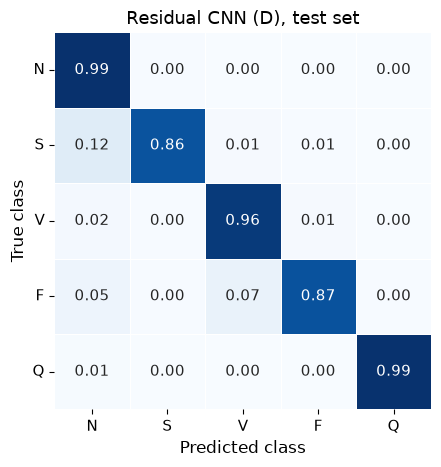

,precision,recall,f1
N,0.993,0.993,0.993
S,0.845,0.864,0.854
V,0.965,0.959,0.962
F,0.784,0.868,0.824
Q,0.995,0.990,0.993


In [8]:
best = "resnet_cnn_D"
y_true_pooled = np.concatenate([y_test] * len(SEEDS))
y_pred_pooled = np.concatenate([test_preds[best, s] for s in SEEDS])

fig, ax = plt.subplots(figsize=(5, 4.8))
plot_confusion_matrix(y_true_pooled, y_pred_pooled, "Residual CNN (D), test set", ax=ax)
fig.tight_layout()
fig.savefig(FIG_DIR / "cm_final_test.png", dpi=200)
plt.show()

pd.DataFrame({c: {k: np.mean([test_metrics[best, s]["per_class"][c][k] for s in SEEDS])
                  for k in ["precision", "recall", "f1"]} for c in CLASS_NAMES}).T.round(3)

## 5. Correct and incorrect predictions

Final model, seed 42. Top row: a correctly classified beat of each class. Bottom row: a misclassified beat of each class, with the predicted label.

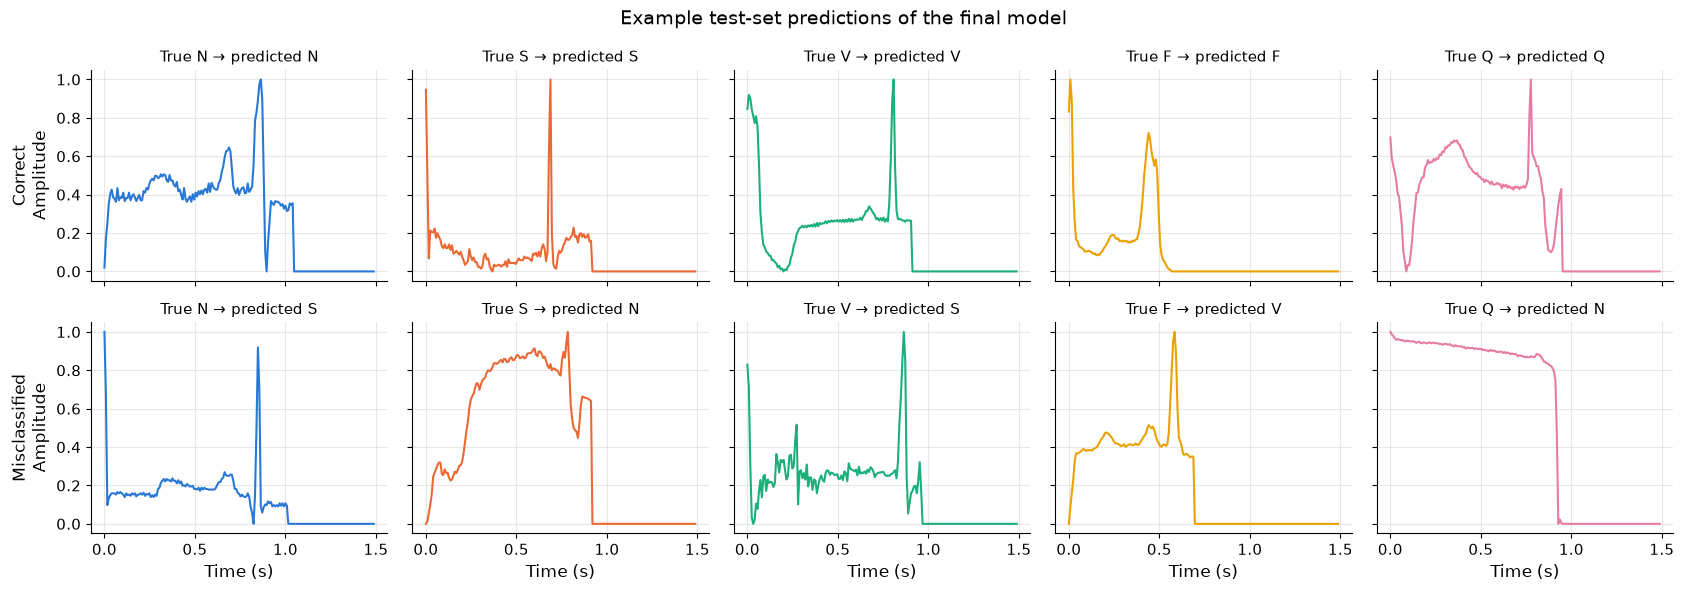

In [9]:
rng = np.random.default_rng(42)
y_pred = test_preds[best, 42]
t = np.arange(X_test.shape[1]) / 125
class_colors = dict(zip(CLASS_NAMES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))

fig, axes = plt.subplots(2, 5, figsize=(17, 6), sharex=True, sharey=True)
for j, cls in enumerate(CLASS_NAMES):
    for i, correct in enumerate([True, False]):
        ax = axes[i, j]
        idx = np.flatnonzero((y_test == j) & ((y_pred == j) == correct))
        if len(idx) == 0:
            ax.text(0.5, 0.5, "no errors", ha="center", va="center", transform=ax.transAxes, color="gray")
        else:
            k = rng.choice(idx)
            ax.plot(t, X_test[k], color=class_colors[cls], linewidth=1.5)
            ax.set_title(f"True {cls} → predicted {CLASS_NAMES[y_pred[k]]}", fontsize=11)
        ax.grid(alpha=0.3)
        ax.spines[["top", "right"]].set_visible(False)
    axes[1, j].set_xlabel("Time (s)")
axes[0, 0].set_ylabel("Correct\nAmplitude")
axes[1, 0].set_ylabel("Misclassified\nAmplitude")
fig.suptitle("Example test-set predictions of the final model", fontsize=14)
fig.tight_layout()
fig.savefig(FIG_DIR / "prediction_examples.png", dpi=200)
plt.show()

## 6. Comparison with the literature

Kachuee et al. (2018) report an *average accuracy* of 93.4% for the same five classes with a residual CNN. Their evaluation set is different from ours: 4,079 held-out beats, about 819 per class, from a dataset that was augmented to balance the classes. The paper does not define "average accuracy" with a formula.

On a balanced test set, overall accuracy equals the mean of the per-class recalls, which is the **balanced accuracy**. Our official test set is strongly imbalanced (83% N), so plain accuracy is dominated by class N. Balanced accuracy is therefore the closest comparable number; plain accuracy is shown as well.

In [10]:
pd.DataFrame({
    "test set": ["4,079 beats, balanced (~819 per class)", "21,892 beats, official split (imbalanced)",
                 "21,892 beats, official split (imbalanced)"],
    "metric": ["average accuracy (as reported)", "accuracy", "balanced accuracy"],
    "value (%)": ["93.4",
                  f"{100 * agg.loc[best, ('accuracy', 'mean')]:.1f} ± {100 * agg.loc[best, ('accuracy', 'std')]:.1f}",
                  f"{100 * agg.loc[best, ('balanced_accuracy', 'mean')]:.1f} ± {100 * agg.loc[best, ('balanced_accuracy', 'std')]:.1f}"],
}, index=["Kachuee et al. (2018)", "This work, residual CNN (D)", "This work, residual CNN (D)"])

,test set,metric,value (%)
Kachuee et al. (2018),"4,079 beats, balanced (~819 per class)",average accuracy (as reported),93.4
"This work, residual CNN (D)","21,892 beats, official split (imbalanced)",accuracy,98.6 ± 0.1
"This work, residual CNN (D)","21,892 beats, official split (imbalanced)",balanced accuracy,93.5 ± 0.1
